# Merge `Decisao` Classes — 10 → 6 (Combined Merge)

`22_Merge_Decisao_Classes.ipynb` folded the three lexical-synonym "confirmed" labels into `CONFIRMADA` (10 → 8).

## Section 1 — Setup & Load

Same source dataset as `22_Merge_Decisao_Classes.ipynb` / `23_Merge_Decisao_Classes_Similarity.ipynb`: `preprocessed_grupo3.csv` (10-class).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

sys.path.insert(0, str(Path('../..').resolve()))
from src.config import DATA_DIR, OUTPUTS_DIR

df = pd.read_csv(DATA_DIR / 'preprocessed_grupo3.csv')
with open(DATA_DIR / 'label2id_grupo3.json', encoding='utf-8') as f:
    label_map_10 = json.load(f)

with open(OUTPUTS_DIR / 'bertimbau' / 'finetune' / 'metrics.json', encoding='utf-8') as f:
    bertimbau_metrics = json.load(f)

cm_labels_10 = bertimbau_metrics['confusion_matrix_labels']
cm_10 = np.array(bertimbau_metrics['confusion_matrix'])
assert cm_labels_10 == label_map_10['labels'], 'Confusion matrix label order has drifted from label2id_grupo3.json'

print(f'Loaded {len(df):,} rows, {df["Decisao"].nunique()} classes')
df['Decisao'].value_counts()

Loaded 10,153 rows, 10 classes


Decisao
CONFIRMADA                        3405
IMPROCEDENTE                      1851
REVOGADA                          1392
PROCEDENTE                         722
NÃO PROVIDO                        579
APELAÇÃO IMPROCEDENTE              540
CONFIRMAÇÃO                        479
REVOGADA EM PARTE                  407
PARCIALMENTE PROCEDENTE            404
CONFIRMADA A DECISÃO RECORRIDA     374
Name: count, dtype: int64

## Section 2 — Collapse-Diagnostic Helper

Collapses a 10x10 confusion matrix along a `CLASS_MERGE_MAP` and recomputes per-class precision/recall/F1 from the collapsed counts.

In [2]:
def collapse_and_score(merge_map: dict, name: str) -> dict:
    assert set(merge_map) == set(cm_labels_10), f'{name}: merge_map missing/extra original labels'
    merged_labels = sorted(set(merge_map.values()))
    midx = {label: i for i, label in enumerate(merged_labels)}

    cm_new = np.zeros((len(merged_labels), len(merged_labels)), dtype=int)
    for i, true_label in enumerate(cm_labels_10):
        for j, pred_label in enumerate(cm_labels_10):
            cm_new[midx[merge_map[true_label]], midx[merge_map[pred_label]]] += cm_10[i, j]

    f1s = {}
    for k, label in enumerate(merged_labels):
        tp = cm_new[k, k]
        fp = cm_new[:, k].sum() - tp
        fn = cm_new[k, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1s[label] = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        'name': name,
        'n_classes': len(merged_labels),
        'accuracy': float(np.trace(cm_new) / cm_new.sum()),
        'macro_f1': float(sum(f1s.values()) / len(f1s)),
        'f1_per_class': f1s,
    }

IDENTITY = {label: label for label in cm_labels_10}
baseline = collapse_and_score(IDENTITY, 'baseline (10-class, actual, no collapse)')
baseline

{'name': 'baseline (10-class, actual, no collapse)',
 'n_classes': 10,
 'accuracy': 0.4143138542350624,
 'macro_f1': 0.37632271068708784,
 'f1_per_class': {'APELAÇÃO IMPROCEDENTE': np.float64(0.242914979757085),
  'CONFIRMADA': np.float64(0.47926267281105994),
  'CONFIRMADA A DECISÃO RECORRIDA': np.float64(0.616822429906542),
  'CONFIRMAÇÃO': np.float64(0.17094017094017094),
  'IMPROCEDENTE': np.float64(0.5490981963927856),
  'NÃO PROVIDO': np.float64(0.6343612334801763),
  'PARCIALMENTE PROCEDENTE': np.float64(0.2258064516129032),
  'PROCEDENTE': np.float64(0.3157894736842105),
  'REVOGADA': np.float64(0.304093567251462),
  'REVOGADA EM PARTE': np.float64(0.22413793103448276)}}

## Section 3 — Compare Merge Candidates

Four candidates, evaluated with the same collapse diagnostic.

In [3]:
CONFIRM_MERGE = {
    'CONFIRMADA A DECISÃO RECORRIDA': 'CONFIRMADA',
    'CONFIRMAÇÃO': 'CONFIRMADA',
}
REVOGADA_PROCEDENTE_MERGE = {
    'REVOGADA EM PARTE': 'REVOGADA',
    'PARCIALMENTE PROCEDENTE': 'PROCEDENTE',
}
DISMISSED_MERGE = {
    'APELAÇÃO IMPROCEDENTE': 'IMPROCEDENTE',
    'NÃO PROVIDO': 'IMPROCEDENTE',
}

def build_map(*merges: dict) -> dict:
    merge_map = dict(IDENTITY)
    for merge in merges:
        merge_map.update(merge)
    return merge_map

candidates = [
    collapse_and_score(build_map(CONFIRM_MERGE), 'A: confirm-family merge only (notebook 22)'),
    collapse_and_score(build_map(REVOGADA_PROCEDENTE_MERGE), 'B: revogada/procedente merge only (notebook 23)'),
    collapse_and_score(build_map(CONFIRM_MERGE, DISMISSED_MERGE), 'C: confirm + dismissed-family merge'),
    collapse_and_score(build_map(CONFIRM_MERGE, REVOGADA_PROCEDENTE_MERGE), 'E: confirm + revogada/procedente merge (chosen)'),
]

summary = pd.DataFrame([
    {'candidate': c['name'], 'n_classes': c['n_classes'], 'accuracy': c['accuracy'], 'macro_f1': c['macro_f1']}
    for c in [baseline, *candidates]
])
summary

,candidate,n_classes,accuracy,macro_f1
0,"baseline (10-class, actual, no collapse)",10,0.414314,0.376323
1,A: confirm-family merge only (notebook 22),8,0.446487,0.380707
2,B: revogada/procedente merge only (notebook 23),8,0.432042,0.421901
3,C: confirm + dismissed-family merge,6,0.477347,0.367858
4,E: confirm + revogada/procedente merge (chosen),6,0.464215,0.442939


Result: candidate E (confirm + revogada/procedente merge) has the highest estimated macro F1 among the 6/8-class options.

In [4]:
CLASS_MERGE_MAP = build_map(CONFIRM_MERGE, REVOGADA_PROCEDENTE_MERGE)

assert set(CLASS_MERGE_MAP) == set(label_map_10['labels']), (
    'CLASS_MERGE_MAP is missing or has extra original labels vs label2id_grupo3.json'
)

n_target_classes = len(set(CLASS_MERGE_MAP.values()))
print(f'{len(CLASS_MERGE_MAP)} original labels -> {n_target_classes} merged classes')
pd.DataFrame(sorted(CLASS_MERGE_MAP.items()), columns=['original_label', 'merged_label'])

10 original labels -> 6 merged classes


,original_label,merged_label
0,APELAÇÃO IMPROCEDENTE,APELAÇÃO IMPROCEDENTE
1,CONFIRMADA,CONFIRMADA
2,CONFIRMADA A DECISÃO RECORRIDA,CONFIRMADA
3,CONFIRMAÇÃO,CONFIRMADA
4,IMPROCEDENTE,IMPROCEDENTE
5,NÃO PROVIDO,NÃO PROVIDO
6,PARCIALMENTE PROCEDENTE,PROCEDENTE
7,PROCEDENTE,PROCEDENTE
8,REVOGADA,REVOGADA
9,REVOGADA EM PARTE,REVOGADA


## Section 4 — Apply the Merge

The original label is kept as `Decisao_original` for traceability; `Decisao` is overwritten with the merged label so every downstream.

In [5]:
df['Decisao_original'] = df['Decisao']
df['Decisao'] = df['Decisao_original'].map(CLASS_MERGE_MAP)

assert df['Decisao'].notna().all(), 'Some rows failed to map -- CLASS_MERGE_MAP is incomplete'
assert len(df) == len(df['Decisao_original'].map(CLASS_MERGE_MAP)), 'Row count changed unexpectedly'

before = df['Decisao_original'].value_counts()
after = df['Decisao'].value_counts()

print(f'Before: {len(before)} classes, {before.sum():,} rows')
print(f'After : {len(after)} classes, {after.sum():,} rows')
assert before.sum() == after.sum(), 'Merge changed the total row count'
after

Before: 10 classes, 10,153 rows
After : 6 classes, 10,153 rows


Decisao
CONFIRMADA               4258
IMPROCEDENTE             1851
REVOGADA                 1799
PROCEDENTE               1126
NÃO PROVIDO               579
APELAÇÃO IMPROCEDENTE     540
Name: count, dtype: int64

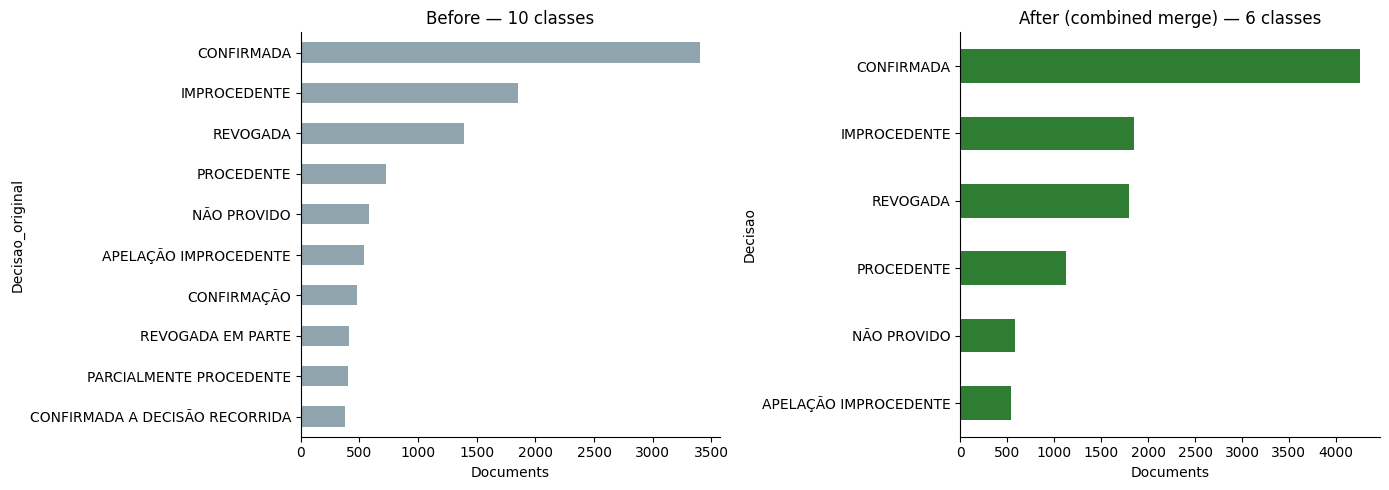

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

before.sort_values().plot.barh(ax=axes[0], color='#90A4AE')
axes[0].set_title(f'Before — {len(before)} classes')
axes[0].set_xlabel('Documents')

after.sort_values().plot.barh(ax=axes[1], color='#2E7D32')
axes[1].set_title(f'After (combined merge) — {len(after)} classes')
axes[1].set_xlabel('Documents')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../../reports/figures/class_distribution_6class.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 5 — Sanity Checks

Same two checks as the earlier merge notebooks: `split` is untouched, and every merged class has at least one row in each of train/val/test.

In [7]:
assert set(df['split'].unique()) <= {'train', 'val', 'test'}

split_counts = df.groupby(['split', 'Decisao']).size().unstack('Decisao').fillna(0).astype(int)
split_counts = split_counts.reindex(['train', 'val', 'test'])
print('Rows per class, per split:')
print(split_counts.T.to_string())

train_classes = set(df.loc[df['split'] == 'train', 'Decisao'].unique())
for other_split in ['val', 'test']:
    split_classes = set(df.loc[df['split'] == other_split, 'Decisao'].unique())
    orphans = train_classes - split_classes
    print(f'\nTrain classes absent from {other_split}: {len(orphans)}')
    assert not orphans, f'{orphans} has zero rows in {other_split} -- cannot be evaluated'

Rows per class, per split:
split                  train  val  test
Decisao                                
APELAÇÃO IMPROCEDENTE    405   54    81
CONFIRMADA              3192  428   638
IMPROCEDENTE            1388  185   278
NÃO PROVIDO              434   58    87
PROCEDENTE               845  112   169
REVOGADA                1350  179   270

Train classes absent from val: 0

Train classes absent from test: 0


## Section 6 — Export

Written next to `preprocessed_grupo3.csv` / `preprocessed_grupo3_8class*.csv` as a distinct file.

In [8]:
EXPORT_COLS = [
    'ImportJurisprudenciaId', 'source', 'Sumario_raw', 'Sumario', 'Decisao', 'Decisao_original',
    'TipoDecisao', 'group_id', 'split', 'cv_fold',
]

export_path = DATA_DIR / 'preprocessed_grupo3_6class.csv'
df[EXPORT_COLS].to_csv(export_path, index=False, encoding='utf-8')
print(f'Exported: {export_path}  ({len(df):,} rows)')

le = LabelEncoder().fit(df['Decisao'])
labels_6 = list(le.classes_)
label2id_6 = {cls: int(i) for i, cls in enumerate(le.classes_)}
id2label_6 = {int(i): cls for i, cls in enumerate(le.classes_)}

label_path = DATA_DIR / 'label2id_grupo3_6class.json'
with open(label_path, 'w', encoding='utf-8') as f:
    json.dump(
        {'labels': labels_6, 'label2id': label2id_6, 'id2label': id2label_6},
        f, ensure_ascii=False, indent=2,
    )
print(f'Label mapping saved -> {label_path}  ({len(label2id_6)} classes)')

Exported: <project>/data/2_processed/preprocessed_grupo3_6class.csv  (10,153 rows)
Label mapping saved -> <project>/data/2_processed/label2id_grupo3_6class.json  (6 classes)
